In [2]:
import numpy as np
import cv2 as cv
import os
import matplotlib.pyplot as plt
import tensorflow.keras as keras
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

Matplotlib is building the font cache; this may take a moment.


In [31]:
datagen = ImageDataGenerator()

In [32]:
# define classes name
class_names = ['major accident', 'minor accident','non Accident']

In [33]:
# training data
train_generator = datagen.flow_from_directory( 
    directory="dataset/train", 
    classes = class_names,
    target_size=(224, 224),  
    batch_size=32, 
    class_mode="categorical", 
)

Found 685 images belonging to 3 classes.


In [34]:
# validation data
valid_generator = datagen.flow_from_directory( 
    directory="dataset/test/", 
    classes = class_names,
    target_size=(224, 224), 
    batch_size=32, 
    class_mode="categorical", 
)

Found 201 images belonging to 3 classes.


In [ ]:
test_generator = datagen.flow_from_directory( 
    directory="dataset/test/", 
    classes = class_names,
    target_size=(224, 224),  
    batch_size=32,  
    class_mode="categorical", 
    shuffle=False
)

Found 201 images belonging to 3 classes.


In [36]:
resnet_50 = ResNet50(include_top=False, weights='imagenet', input_shape=(224,224,3))
for layer in resnet_50.layers:
    layer.trainable = False

In [37]:
x = resnet_50.output
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(512, activation='relu')(x) 
x = layers.Dropout(0.5)(x)
x = layers.Dense(256, activation='relu')(x) 
x = layers.Dropout(0.5)(x)
x = layers.Dense(128, activation='relu')(x) 
x = layers.Dropout(0.5)(x)
x = layers.Dense(64, activation='relu')(x) 
x = layers.Dropout(0.5)(x)
predictions = layers.Dense(3, activation='softmax')(x)
model = Model(inputs = resnet_50.input, outputs = predictions)

In [38]:
import tensorflow as tf
from tensorflow.keras.callbacks import ModelCheckpoint

def trainModel(model, epochs, optimizer):
    batch_size = 32
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    checkpoint = ModelCheckpoint(
            "model_weights.keras",  # Adjust filepath to end with '.keras'
            monitor='val_accuracy',
            verbose=1,
            save_best_only=True,
            mode='max'
        )
    callbacks_list = [checkpoint]
    return model.fit(train_generator, validation_data=valid_generator, epochs=epochs, batch_size=batch_size, callbacks=callbacks_list)

In [39]:
model_history = trainModel(model = model, epochs = 10, optimizer = "Adam")

Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5290 - loss: 1.8969
Epoch 1: val_accuracy improved from -inf to 0.69154, saving model to model_weights.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 75s 3s/step - accuracy: 0.5312 - loss: 1.8916 - val_accuracy: 0.6915 - val_loss: 0.8503
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6197 - loss: 1.2028
Epoch 2: val_accuracy improved from 0.69154 to 0.74627, saving model to model_weights.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 64s 3s/step - accuracy: 0.6204 - loss: 1.1953 - val_accuracy: 0.7463 - val_loss: 0.6749
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7252 - loss: 0.7838
Epoch 3: val_accuracy improved from 0.74627 to 0.75622, saving model to model_weights.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 68s 3s/step - accuracy: 0.7257 - loss: 0.7827 - val_accuracy: 0.7562 - val_loss: 0.6009
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7894 - loss: 0.5938
Epoch 4: val_accuracy did not improve from 0.75622

In [40]:
model_json = model.to_json()
with open("model.json", "w") as json_file:
    json_file.write(model_json)

model.save("model6.h5")

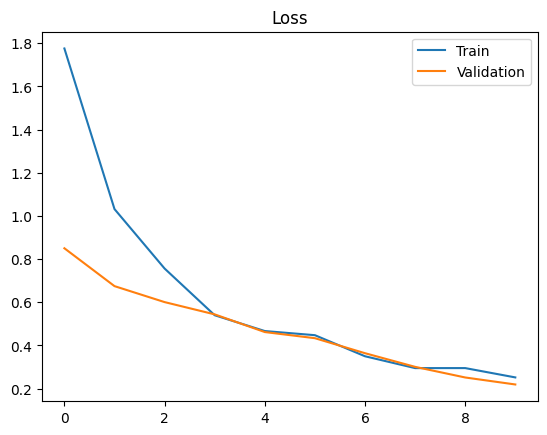

In [41]:
loss_train_curve = model_history.history["loss"]
loss_val_curve = model_history.history["val_loss"]
plt.plot(loss_train_curve, label = "Train")
plt.plot(loss_val_curve, label = "Validation")
plt.legend(loc = 'upper right')
plt.title("Loss")
plt.show()

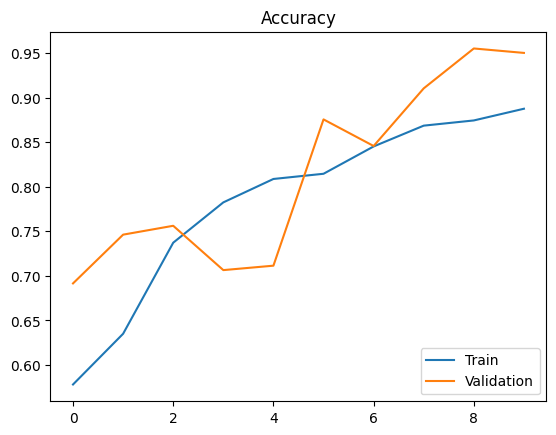

In [42]:
acc_train_curve = model_history.history["accuracy"]
acc_val_curve = model_history.history["val_accuracy"]
plt.plot(acc_train_curve, label = "Train")
plt.plot(acc_val_curve, label = "Validation")
plt.legend(loc = 'lower right')
plt.title("Accuracy")
plt.show()

7/7 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step


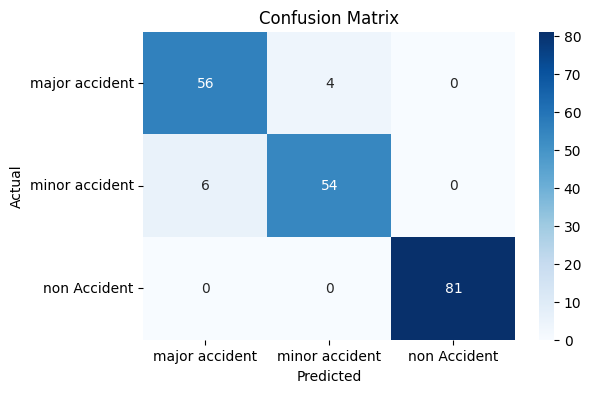

Precision: 0.9505254594657413
Recall: 0.9502487562189055
F1 Score: 0.9502349325890691

Classification Report:

                precision    recall  f1-score   support

major accident       0.90      0.93      0.92        60
minor accident       0.93      0.90      0.92        60
  non Accident       1.00      1.00      1.00        81

      accuracy                           0.95       201
     macro avg       0.94      0.94      0.94       201
  weighted avg       0.95      0.95      0.95       201



In [45]:
from sklearn.metrics import confusion_matrix, classification_report, precision_score, recall_score, f1_score
import seaborn as sns

# Reset generator
test_generator.reset()

# Get predictions
pred_probs = model.predict(test_generator)
y_pred = np.argmax(pred_probs, axis=1)
y_true = test_generator.classes

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Precision, Recall, F1
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

# Detailed Classification Report
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))

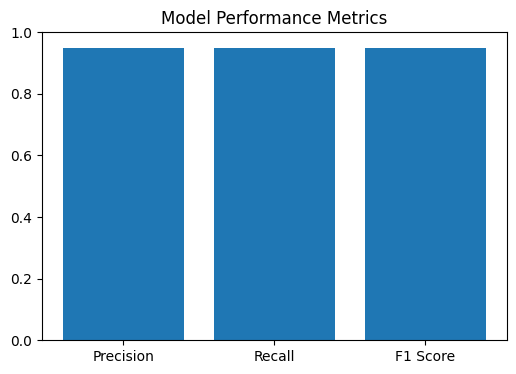

In [44]:
metrics = ['Precision', 'Recall', 'F1 Score']
values = [precision, recall, f1]

plt.figure(figsize=(6,4))
plt.bar(metrics, values)
plt.ylim(0,1)
plt.title("Model Performance Metrics")
plt.show()

In [15]:
test_loss, test_acc = model.evaluate(test_generator)
print("The test loss is: ", test_loss)
print("The best accuracy is: ", test_acc*100)

7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 5s/step - accuracy: 1.0000 - loss: 0.0039
The test loss is:  0.0030416641384363174
The best accuracy is:  100.0


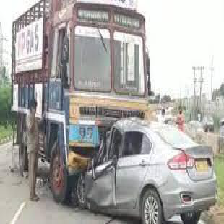

In [ ]:
img = tf.keras.preprocessing.image.load_img('image1.jpg', target_size=(224, 224))
img_array = tf.keras.preprocessing.image.img_to_array(img)
img_array = np.array([img_array]) 
img

In [ ]:
# generate predictions for samples
predictions = model.predict(img_array)  
print(predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 14s 14s/step
[[1.000000e+00 1.015350e-08 5.975185e-10]]


In [ ]:
class_names = ['major accident', 'minor accident', 'non Accident']

predicted_index = np.argmax(predictions)

predicted_class = class_names[predicted_index]

print(f"Predicted class: {predicted_class}")